<center>

 UNIVERSIDAD NACIONAL AUTÓNOMA DE MÉXICO
  
Instituto de Astronomía

<center>

<center> <b> Proyecto Final: Clasificación morfológica de galaxias </b> <center>

<center>

<b> Alumno: </b> Luis Ángel Quiroz López<p>
<b> Profesor: </b> Dr. José Antonio De Diego Onsurbe <p>
<b> Materia: </b> Introducción a Redes Neuronales <p>

<center>

# Preámbulo

In [ ]:
# Cargar Google Drive donde se encuentran los datos e imágenes.
from google.colab import drive
drive.mount('/content/drive')

# Librerías utilizadas

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from keras import Input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Perfil de datos

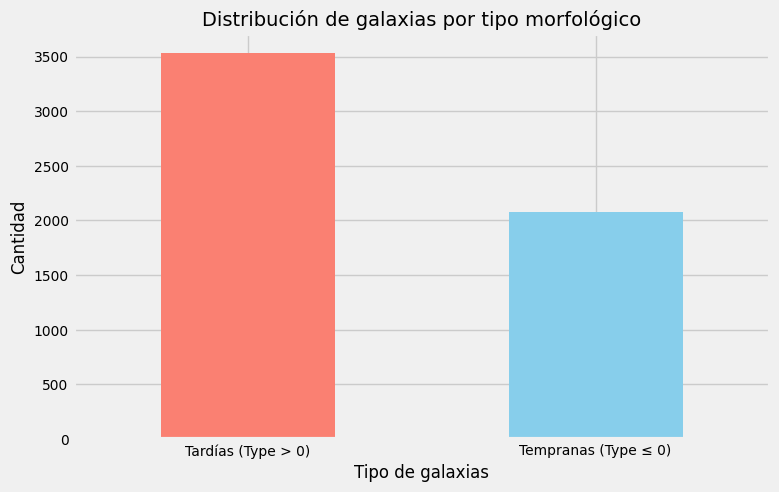

In [ ]:
# Configurar el estilo
plt.style.use('fivethirtyeight')

# Cargar el archivo CSV
file_path = "/content/drive/MyDrive/galaxiesSample/galaxias.csv"
data = pd.read_csv(file_path)

# Crear las categorías de tempranas (elípticas) y tardías (espirales e irregulares)
data['Category'] = data['Type'].apply(lambda x: 'Tempranas (Type ≤ 0)' if x <= 0 else 'Tardías (Type > 0)')

# Histograma con colores distintos
plt.figure(figsize=(8, 5))
colors = {'Tempranas (Type ≤ 0)': 'skyblue', 'Tardías (Type > 0)': 'salmon'}
data['Category'].value_counts().plot(
    kind='bar',
    color=[colors[cat] for cat in data['Category'].value_counts().index]
)
plt.title('Distribución de galaxias por tipo morfológico', fontsize=14)
plt.xlabel('Tipo de galaxias', fontsize=12)
plt.ylabel('Cantidad', fontsize=12)
plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)
plt.show()


In [ ]:
# Definir directorio de imágenes
image_dir = "/content/drive/MyDrive/galaxiesSample"

# Cargar el CSV con los datos
data = pd.read_csv('/content/drive/MyDrive/galaxiesSample/galaxias.csv')

# Filtrar solo las filas con imágenes correspondientes
data['image_path'] = data['name'].apply(lambda x: os.path.join(image_dir, x + '.jpg'))  # Ruta completa de las imágenes

# Hacer una copia del DataFrame para evitar modificaciones en una vista
data = data[data['image_path'].apply(lambda x: os.path.exists(x))].copy()  # Asegurarnos de trabajar con una copia

# Generar clases a partir de 'Type'
data.loc[:, 'label'] = data['Type'].apply(lambda x: 'tempranas' if x <= 0 else 'tardias')

In [ ]:
print(data.columns)  # Verifica las columnas del DataFrame
print(data.head())   # Revisa los primeros valores

Index(['name', 'Type', 'Bars', 'Tidal', 'g-i', 'image_path', 'label'], dtype='object')
              name  Type  Bars  Tidal     g-i  \
0  manga-8947-1902  -5.0   0.0    0.0  1.1157   
1  manga-8481-1901  -5.0   0.0    0.0 -0.1324   
2  manga-9196-6102  -5.0   0.0    0.0  1.1801   
3  manga-9512-3703  -5.0   0.0    0.0  1.0456   
4  manga-7964-1901  -5.0   0.0    1.0  0.9352   

                                          image_path      label  
0  /content/drive/MyDrive/galaxiesSample/manga-89...  tempranas  
1  /content/drive/MyDrive/galaxiesSample/manga-84...  tempranas  
2  /content/drive/MyDrive/galaxiesSample/manga-91...  tempranas  
3  /content/drive/MyDrive/galaxiesSample/manga-95...  tempranas  
4  /content/drive/MyDrive/galaxiesSample/manga-79...  tempranas  


## Pre-procesamiento

In [ ]:
# Dividir los datos en 85% para entrenamiento/validación y 15% para prueba
train_val_data, test_data = train_test_split(data, test_size=0.15, random_state=42)

# Dividir el 85% restante en 70% para entrenamiento y 15% para validación
train_data, val_data = train_test_split(train_val_data, test_size=0.15/0.85, random_state=42)

# Verificar los tamaños de los conjuntos
print(f"Total imágenes: {len(data)}")
print(f"Entrenamiento: {len(train_data)}")
print(f"Validación: {len(val_data)}")
print(f"Prueba: {len(test_data)}")

Total imágenes: 5608
Entrenamiento: 3924
Validación: 842
Prueba: 842


In [ ]:
# Normalización
datagen = ImageDataGenerator(rescale=1./255)

# Crear generadores para entrenamiento, validación y prueba
train_generator = datagen.flow_from_dataframe(
    dataframe=train_data,
    directory=image_dir,
    x_col='image_path',
    y_col='label',
    class_mode='binary',
    target_size=(150, 150),
    batch_size=32
)

val_generator = datagen.flow_from_dataframe(
    dataframe=val_data,
    directory=image_dir,
    x_col='image_path',
    y_col='label',
    class_mode='binary',
    target_size=(150, 150),
    batch_size=32
)

test_generator = datagen.flow_from_dataframe(
    dataframe=test_data,
    directory=image_dir,
    x_col='image_path',
    y_col='label',
    class_mode='binary',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False  # Para mantener el orden y facilitar la evaluación
)


Found 3924 validated image filenames belonging to 2 classes.
Found 842 validated image filenames belonging to 2 classes.
Found 842 validated image filenames belonging to 2 classes.


# Modelo 1

In [ ]:
# Crear el modelo
model = Sequential([
      Input(shape=(150, 150, 3)),
      Conv2D(32, (3, 3), activation='relu'),
      MaxPooling2D(2, 2),
      Conv2D(64, (3, 3), activation='relu'),
      MaxPooling2D(2, 2),
      Flatten(),
      Dense(64, activation='relu'),
      Dropout(0.5),
      Dense(1, activation='sigmoid')
  ])

# Compilar el modelo
model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

# Entrenar el modelo con EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=50,
    callbacks=[early_stopping]
)

# Evaluar el modelo en el conjunto de prueba
test_loss, test_accuracy = model.evaluate(test_generator)

# Imprimir los resultados de la evaluación
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")


Epoch 1/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 189s 1s/step - accuracy: 0.6362 - loss: 0.8530 - val_accuracy: 0.8100 - val_loss: 0.4448
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 182s 1s/step - accuracy: 0.7831 - loss: 0.4817 - val_accuracy: 0.8337 - val_loss: 0.4143
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 218s 2s/step - accuracy: 0.7940 - loss: 0.4565 - val_accuracy: 0.8325 - val_loss: 0.4009
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 191s 2s/step - accuracy: 0.8047 - loss: 0.4268 - val_accuracy: 0.8171 - val_loss: 0.4141
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 192s 2s/step - accuracy: 0.8234 - loss: 0.4167 - val_accuracy: 0.8397 - val_loss: 0.3696
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.8184 - loss: 0.4102 - val_accuracy: 0.8504 - val_loss: 0.3639
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 193s 2s/step - accuracy: 0.8350 - loss: 0.3751 - val_accuracy: 0.8492 - val_loss: 0.4089
Epoch 8/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 184s 1s/step - accuracy: 0.8302 - loss: 0.3688 - val_accu

## Análisis de resultados

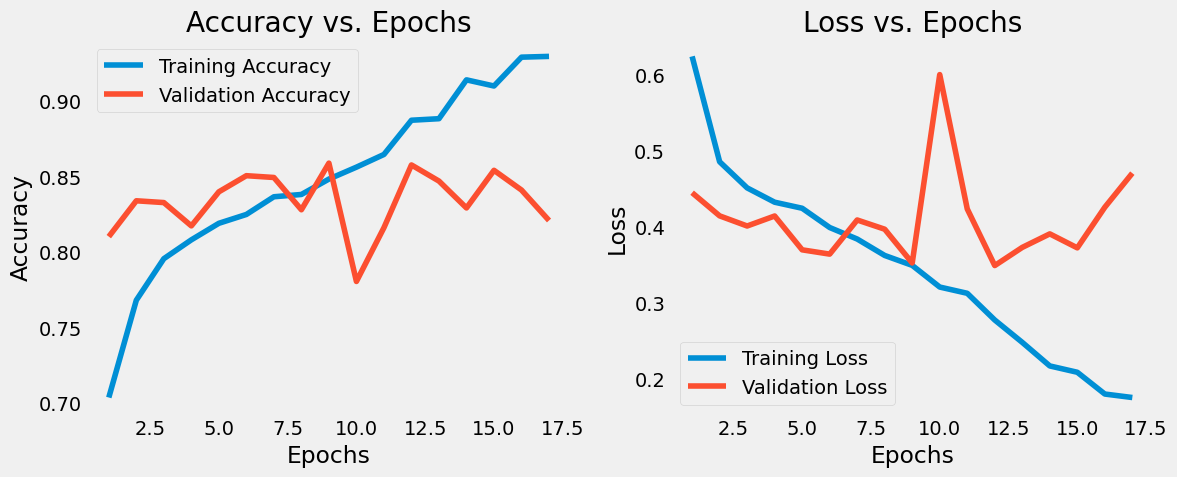

27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 536ms/step


In [ ]:
# Graficar la pérdida (loss) y precisión (accuracy) durante el entrenamiento
def plot_training_history(history):
    # Extraer las métricas del entrenamiento
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    # Gráfica de la precisión
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Training Accuracy')
    plt.plot(epochs, val_acc, label='Validation Accuracy')
    plt.title('Accuracy vs. Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid()

    # Gráfica de la pérdida
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Training Loss')
    plt.plot(epochs, val_loss, label='Validation Loss')
    plt.title('Loss vs. Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()

# Generar las gráficas de pérdida y precisión
plot_training_history(history)

# Predecir en el conjunto de prueba
y_pred = model.predict(test_generator)
y_pred_labels = np.where(y_pred > 0.5, 1, 0)  # Umbral de 0.5 para clasificación binaria

# Obtener etiquetas reales del conjunto de prueba
y_true = test_generator.classes

27/27 ━━━━━━━━━━━━━━━━━━━━ 14s 529ms/step


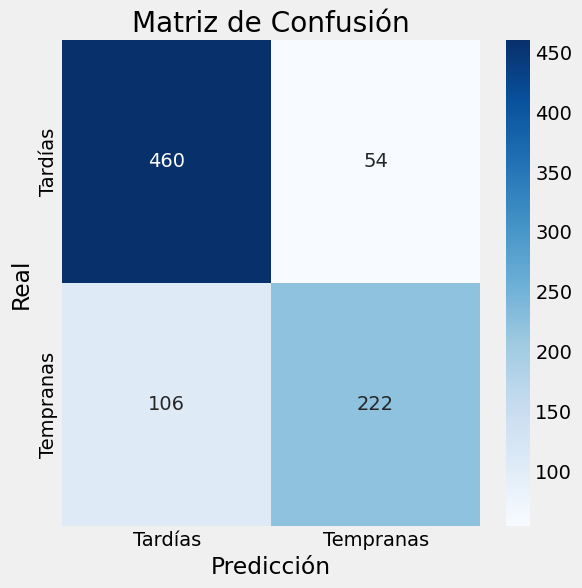

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       514
           1       0.80      0.68      0.74       328

    accuracy                           0.81       842
   macro avg       0.81      0.79      0.79       842
weighted avg       0.81      0.81      0.81       842



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
from sklearn.metrics import roc_auc_score

# Asegúrate de que los datos y el modelo estén preparados como antes

# Obtener las predicciones del modelo
y_true = test_generator.classes  # Etiquetas reales
y_pred_proba = model.predict(test_generator)  # Predicciones de probabilidad
y_pred = (y_pred_proba > 0.5).astype(int)  # Convertir las predicciones a 0 o 1

# Matriz de Confusión
cm = confusion_matrix(y_true, y_pred)

# Graficar la matriz de confusión
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Tardías', 'Tempranas'], yticklabels=['Tardías', 'Tempranas'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión')
plt.show()

# Reporte de Clasificación: Precisión, Recall, F1-Score
print("Reporte de clasificación:")
print(classification_report(y_true, y_pred))

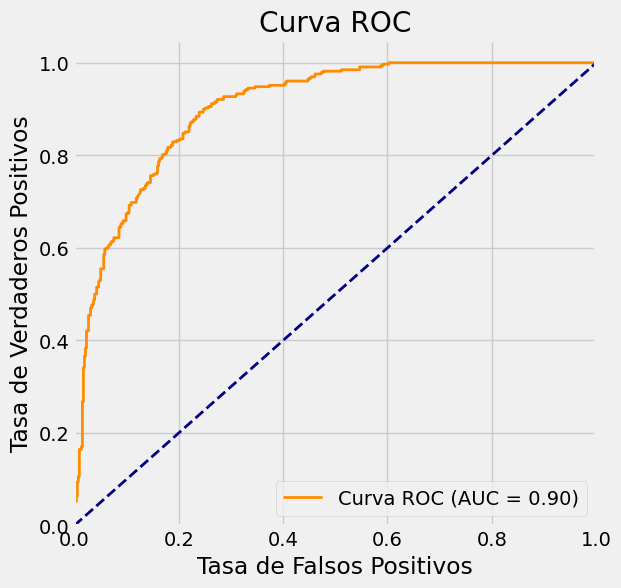

In [ ]:
# Curva ROC y AUC
fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Graficar la curva ROC
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.show()

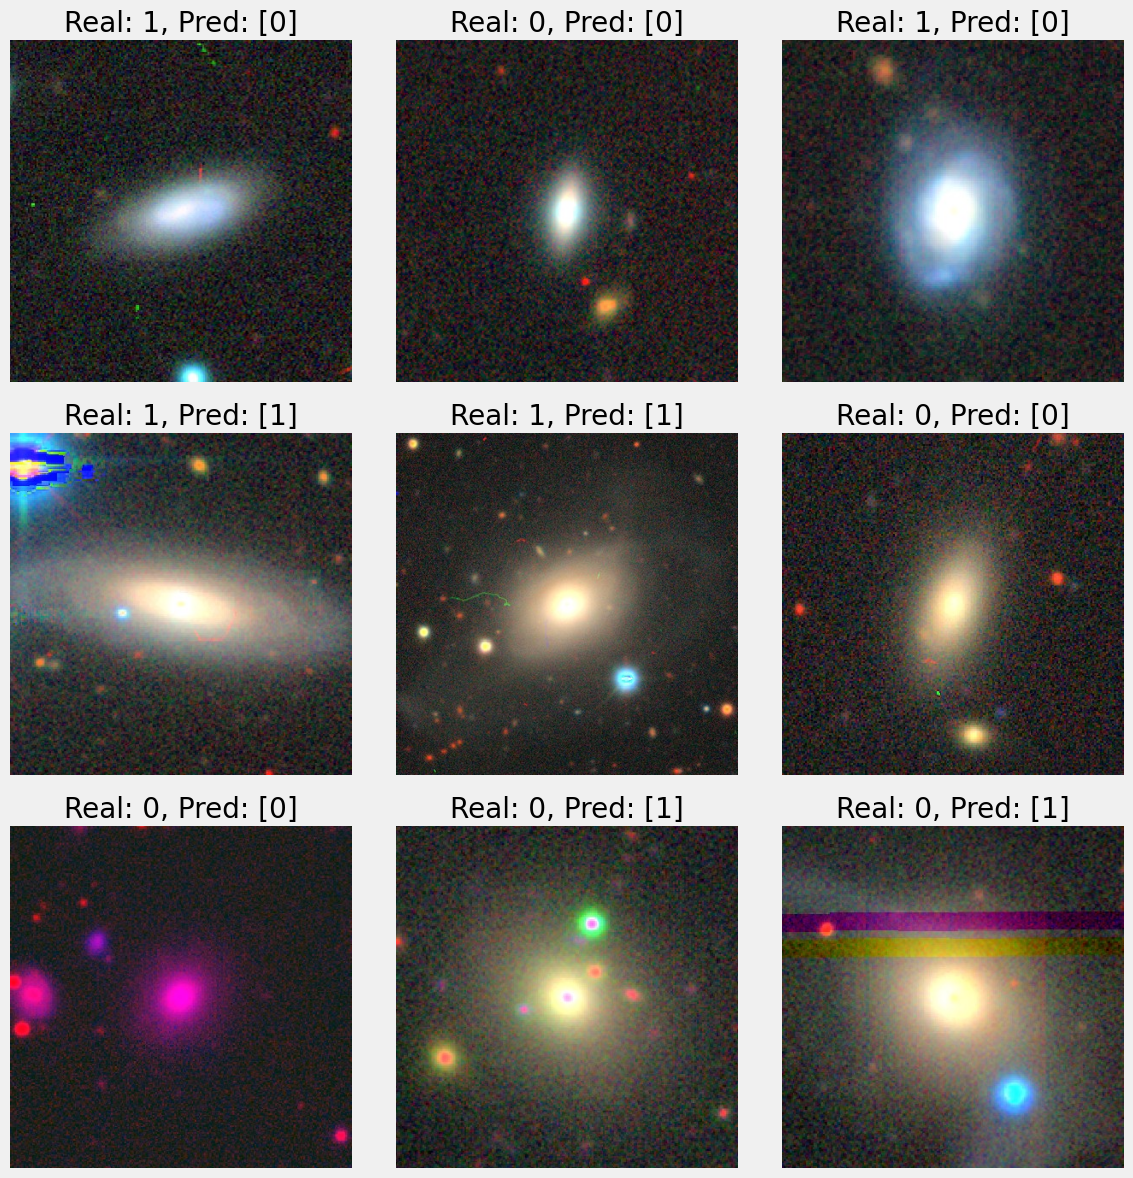

         Image Name  Real Label Predicted Label     g-i  Bars  Tidal
0   manga-8147-3701           1             [0]  0.5855  0.50    0.0
1  manga-10507-1901           0             [0]  0.7140  0.00    0.0
2   manga-8455-3701           1             [0]  0.8691  0.75    0.0
3   manga-8606-3702           1             [1]  1.1357  0.00    0.0
4   manga-8154-6103           1             [1]  1.1478  0.00    1.0
5  manga-8942-12701           0             [0]  1.2668  0.00    0.0
6   manga-8712-3701           0             [0]  0.9827  0.00    0.0
7   manga-8484-9102           0             [1]  1.1277  0.00    0.0
8   manga-8247-6101           0             [1]  1.4155  0.00    1.0


In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cargar el CSV con los datos
data = pd.read_csv('/content/drive/MyDrive/galaxiesSample/galaxias.csv')

# Normalizar las etiquetas reales: 0 para "tempranas", 1 para "tardías"
data['Normalized Real Label'] = data['Type'].apply(lambda x: 0 if x <= 0 else 1)

# Suponiendo que 'y_pred' son las predicciones y 'y_true' son las etiquetas reales
# 'test_generator' es el generador que devuelve las imágenes en el conjunto de prueba

# Predicciones incorrectas
incorrect_predictions = np.where(y_pred != y_true)[0]

# Asegurarse de que haya suficientes imágenes incorrectas para seleccionar
if len(incorrect_predictions) >= 9:
    random_incorrect_predictions = random.sample(list(incorrect_predictions), 9)
else:
    random_incorrect_predictions = incorrect_predictions  # Si no hay suficientes, muestra todas las incorrectas

# Crear una lista para almacenar los datos de la tabla
table_data = []

# Graficar algunas imágenes con sus predicciones incorrectas aleatorias
plt.figure(figsize=(12, 12))
for i, idx in enumerate(random_incorrect_predictions):  # Muestra 9 predicciones incorrectas aleatorias
    img_path = test_generator.filenames[idx]  # Obtener el path de la imagen
    img = plt.imread(img_path)

    plt.subplot(3, 3, i+1)
    plt.imshow(img)

    # Obtener el nombre de la imagen
    img_name = img_path.split('/')[-1].replace('.jpg', '')  # Obtener el nombre sin la extensión .jpg

    # Buscar la fila correspondiente en el CSV usando el nombre de la imagen
    image_data = data[data['name'] == img_name]

    if image_data.empty:
        print(f"Advertencia: {img_name} no encontrado en el CSV")
    else:
        image_data = image_data.iloc[0]

        # Añadir la información a la tabla
        table_data.append({
            'Image Name': img_name,
            'Real Label': image_data['Normalized Real Label'],  # Usar la etiqueta normalizada
            'Predicted Label': y_pred[idx],
            'g-i': image_data['g-i'],
            'Bars': image_data['Bars'],
            'Tidal': image_data['Tidal']
        })

    # Mostrar la predicción y el valor real
    plt.title(f"Real: {image_data['Normalized Real Label'] if not image_data.empty else 'N/A'}, Pred: {y_pred[idx]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Crear un DataFrame con los datos de la tabla
results_df = pd.DataFrame(table_data)

# Mostrar la tabla con los resultados
print(results_df)


# Modelo 2

Epoch 1/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 249s 2s/step - accuracy: 0.6553 - loss: 0.6274 - val_accuracy: 0.8029 - val_loss: 0.4307
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 236s 2s/step - accuracy: 0.7814 - loss: 0.4659 - val_accuracy: 0.8147 - val_loss: 0.4051
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 263s 2s/step - accuracy: 0.8018 - loss: 0.4482 - val_accuracy: 0.8254 - val_loss: 0.3917
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 265s 2s/step - accuracy: 0.8035 - loss: 0.4232 - val_accuracy: 0.8314 - val_loss: 0.3825
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 242s 2s/step - accuracy: 0.8323 - loss: 0.3969 - val_accuracy: 0.8420 - val_loss: 0.3652
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 234s 2s/step - accuracy: 0.8294 - loss: 0.3849 - val_accuracy: 0.8361 - val_loss: 0.3593
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 237s 2s/step - accuracy: 0.8405 - loss: 0.3692 - val_accuracy: 0.8492 - val_loss: 0.3493
Epoch 8/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 262s 2s/step - accuracy: 0.8490 - loss: 0.3470 - val_accu

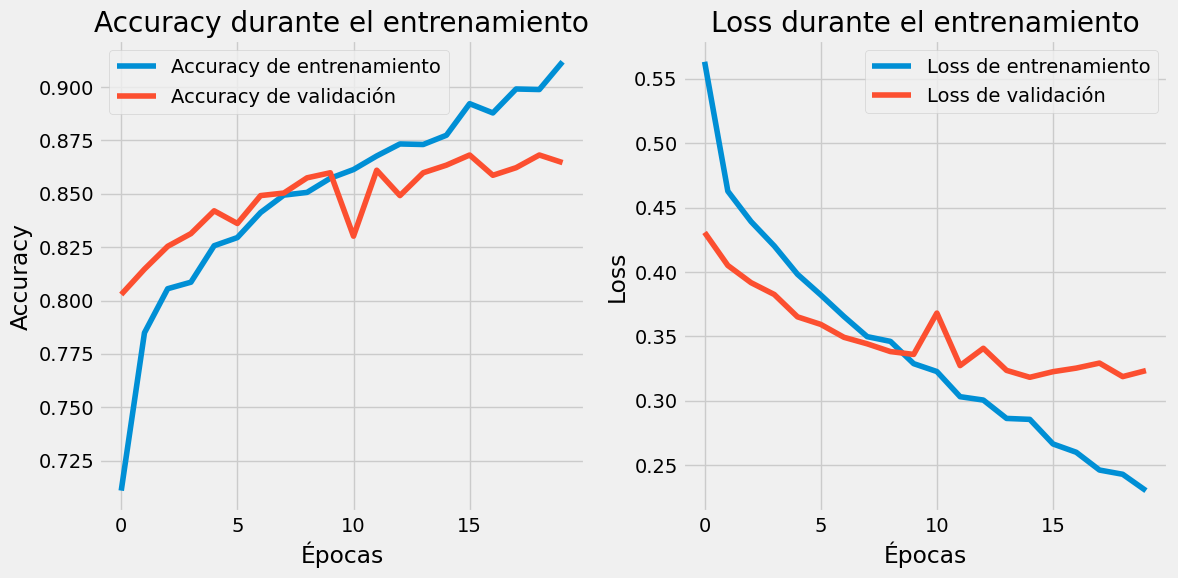

27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 626ms/step


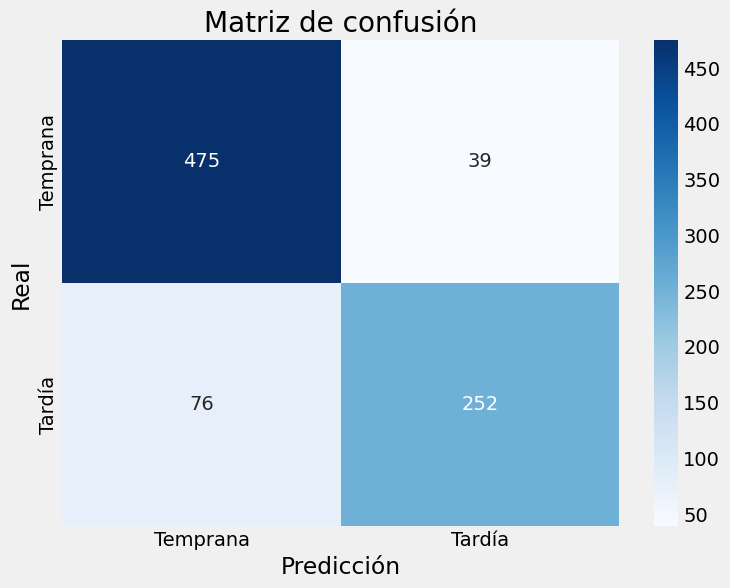

Reporte de clasificación:
              precision    recall  f1-score   support

    Temprana       0.86      0.92      0.89       514
      Tardía       0.87      0.77      0.81       328

    accuracy                           0.86       842
   macro avg       0.86      0.85      0.85       842
weighted avg       0.86      0.86      0.86       842



In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Crear el modelo mejorado
model = Sequential([
    Input(shape=(150, 150, 3)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# Compilar el modelo
model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

# Entrenar el modelo
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=50,
    callbacks=[early_stopping]
)

# Evaluar el modelo
test_loss, test_accuracy = model.evaluate(test_generator)

# Resultados
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

# Graficar accuracy y loss
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Accuracy de entrenamiento')
plt.plot(history.history['val_accuracy'], label='Accuracy de validación')
plt.title('Accuracy durante el entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Loss de entrenamiento')
plt.plot(history.history['val_loss'], label='Loss de validación')
plt.title('Loss durante el entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Predicciones en el conjunto de prueba
y_pred = model.predict(test_generator)
y_pred_binary = (y_pred > 0.5).astype(int)

# Obtener etiquetas reales
y_true = test_generator.classes

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred_binary)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Temprana', 'Tardía'], yticklabels=['Temprana', 'Tardía'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de confusión')
plt.show()

# Reporte de clasificación
print("Reporte de clasificación:")
print(classification_report(y_true, y_pred_binary, target_names=['Temprana', 'Tardía']))


# InceptionV3

Epoch 1/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 320s 2s/step - accuracy: 0.7631 - loss: 0.5538 - val_accuracy: 0.8468 - val_loss: 0.3953
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 258s 2s/step - accuracy: 0.8616 - loss: 0.3425 - val_accuracy: 0.8432 - val_loss: 0.3702
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 294s 2s/step - accuracy: 0.9070 - loss: 0.2338 - val_accuracy: 0.8527 - val_loss: 0.3421
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 255s 2s/step - accuracy: 0.9216 - loss: 0.2015 - val_accuracy: 0.8349 - val_loss: 0.4125
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 279s 2s/step - accuracy: 0.9210 - loss: 0.2082 - val_accuracy: 0.8397 - val_loss: 0.3818
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 258s 2s/step - accuracy: 0.9396 - loss: 0.1549 - val_accuracy: 0.8456 - val_loss: 0.3981
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 257s 2s/step - accuracy: 0.9404 - loss: 0.1501 - val_accuracy: 0.8409 - val_loss: 0.4085
Epoch 8/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 255s 2s/step - accuracy: 0.9610 - loss: 0.1064 - val_accu

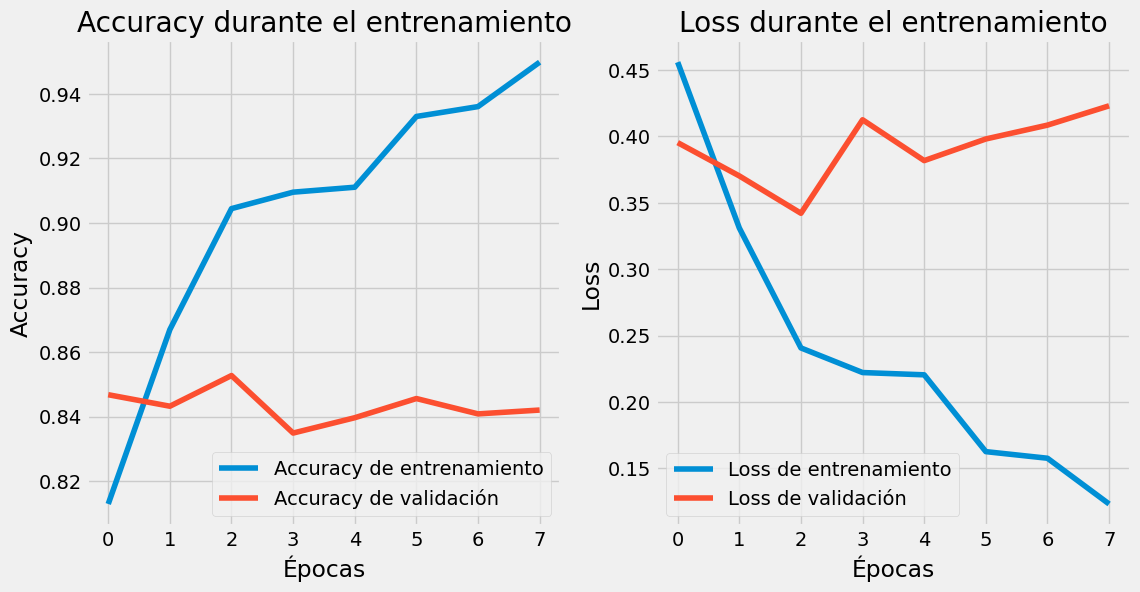

27/27 ━━━━━━━━━━━━━━━━━━━━ 51s 2s/step
[[440  74]
 [ 45 283]]


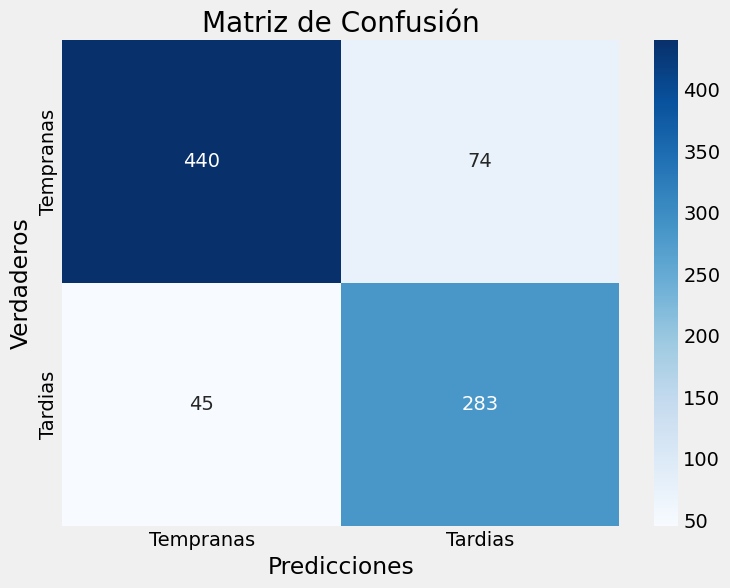

              precision    recall  f1-score   support

           0       0.91      0.86      0.88       514
           1       0.79      0.86      0.83       328

    accuracy                           0.86       842
   macro avg       0.85      0.86      0.85       842
weighted avg       0.86      0.86      0.86       842



In [ ]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Cargar el modelo preentrenado InceptionV3 sin las capas finales (sin la capa de clasificación)
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(150, 150, 3))

# Congelar las capas base para evitar que se entrenen durante el fine-tuning
base_model.trainable = False

# Crear el modelo de clasificación
model = Model(inputs=base_model.input,
              outputs=Dense(1, activation='sigmoid')(Flatten()(base_model.output)))

# Compilar el modelo
model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

# Generadores para cargar las imágenes de entrenamiento y validación
train_datagen = ImageDataGenerator(rescale=1./255,
                                   rotation_range=20,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True)

val_datagen = ImageDataGenerator(rescale=1./255)

# Entrenar el modelo con EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=50,
    callbacks=[early_stopping]
)

# Evaluar el modelo en el conjunto de prueba
test_loss, test_accuracy = model.evaluate(test_generator)

# Imprimir los resultados de la evaluación
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

# Graficar las métricas de entrenamiento y validación
plt.figure(figsize=(12, 6))

# Accuracy del entrenamiento
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Accuracy de entrenamiento')
plt.plot(history.history['val_accuracy'], label='Accuracy de validación')
plt.title('Accuracy durante el entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()

# Loss del entrenamiento
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Loss de entrenamiento')
plt.plot(history.history['val_loss'], label='Loss de validación')
plt.title('Loss durante el entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()

plt.show()

# Predicciones en el conjunto de prueba
predictions = model.predict(test_generator)
predictions = (predictions > 0.5)  # Umbral para la clasificación binaria

# Obtener las etiquetas verdaderas
true_labels = test_generator.classes

# Calcular la matriz de confusión
conf_matrix = confusion_matrix(true_labels, predictions)
print(conf_matrix)

# Mostrar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['Tempranas', 'Tardias'], yticklabels=['Tempranas', 'Tardias'])
plt.title('Matriz de Confusión')
plt.ylabel('Verdaderos')
plt.xlabel('Predicciones')
plt.show()

# Reporte de clasificación
print(classification_report(true_labels, predictions))
